# CS 4789 PA3: Balloon Navigation

This notebook is the main entry point for the assignment. Use it to:
1. install dependencies and (optionally) mount Google Drive,
2. run the provided sanity tests,
3. launch the Section 6 experiments, and
4. generate the figures needed for the Section 7 writeup.

Implementations live in `DP.py`, `VI.py`, and `Qlearning.py`. Plotting helpers and experiment runners live in `visualize.py`.

## 0. Setup

On Colab, mount Drive and `cd` into the folder that contains this notebook (and `MDP.py` / `DP.py` / ...). Locally, skip the Drive cells and just make sure your working directory is the PA3 folder.

In [12]:
# Colab only — skip locally.
try:
    from google.colab import drive

    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Not running on Colab; skipping Drive mount.")

Not running on Colab; skipping Drive mount.


In [13]:
# Colab only: set this to your PA3 folder on Drive, then uncomment.
# TARGET_DIR = "/content/drive/MyDrive/CS4789/PA3"
# %cd "$TARGET_DIR"
!ls

DP.py            SOLUTION         figures          setup.py
MDP.py           VI.py            handout.pdf      test.py
Qlearning.py     __pycache__      requirements.txt visualize.py
README.md        colab.ipynb      run.py


In [14]:
!pip install -q -r requirements.txt
# or: !pip install -q -e .


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [ ]:
import time

import matplotlib.pyplot as plt
import torch

from MDP import build_default_balloon_mdp
from DP import DynamicProgramming
from VI import ValueIteration
from Qlearning import QLearning

import importlib
import visualize

importlib.reload(visualize)
from visualize import (
    plot_environment,
    plot_value_and_policy,
    plot_q_function,
    plot_learning_curve,
    run_dp_horizon_sweep,
    run_dp_time_slices,
    run_vi_propagation,
    run_vi_discount_sweep,
    run_qlearning_experiments,
    run_all_experiments,
)

device = "cpu"
print(f"torch {torch.__version__}, device = {device}")
SAVE_DIR = "figures"

torch 2.14.0, device = cpu


## 1. Sanity tests

Passing these does **not** guarantee correctness — also inspect the plots in Section 2–4.

In [16]:
!python test.py


 Running all sanity tests

 MDP sanity tests

-- Shapes and basic properties
  [PASS] P/R shapes correct and P is a valid distribution over next states
  [PASS] initial/goal states and goal-state absorption are correct

-- Example transitions from Figure 1
  [PASS] all four worked examples from Figure 1 match

----------------------------------------------------------------
 MDP suite: 3 checks passed
----------------------------------------------------------------

 Dynamic Programming (finite horizon) sanity tests

-- computeQfromV
  [PASS] Q = R when V_{t+1} = 0
  [PASS] Q(s,a) = R(s,a) + E[V_{t+1}(s')] for a random V_{t+1}

-- dynamicProgramming
  [PASS] pi/V have shape (horizon, nStates)
  [PASS] V[t]/pi[t] are consistent with the backward recursion for every t

----------------------------------------------------------------
 DP suite: 4 checks passed
----------------------------------------------------------------

 Value Iteration (infinite horizon) sanity tests

-- computeVfr

## 2. Environment

Wind field for the default 6×6 map (Figure 1 orientation: `j` increases upward).

Saved figures/environment_wind.png


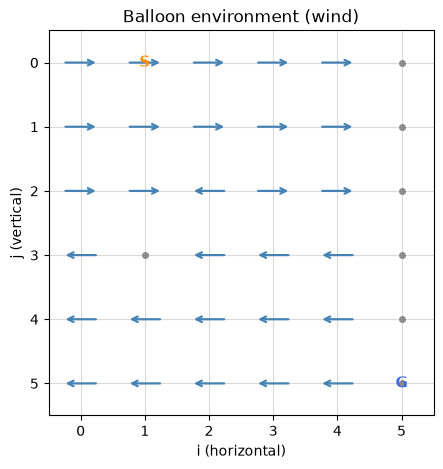

In [17]:
mdp = build_default_balloon_mdp(discount=0.9, device=device)
plot_environment(mdp, save_path=f"{SAVE_DIR}/environment_wind.png")
plt.show()

## 3. Section 6.1 — Finite-horizon dynamic programming

Run DP for horizons $H \in \{2,5,10,20\}$ and plot $V^*_0$, $\pi^*_0$.  
Then, for a longer horizon, step through time-dependent $(V^*_t, \pi^*_t)$.

DP H=2: V*_0(s0) = -2.00
DP H=5: V*_0(s0) = -5.00
DP H=10: V*_0(s0) = 14.00
DP H=20: V*_0(s0) = 14.00
Saved figures/dp_horizon_sweep.png


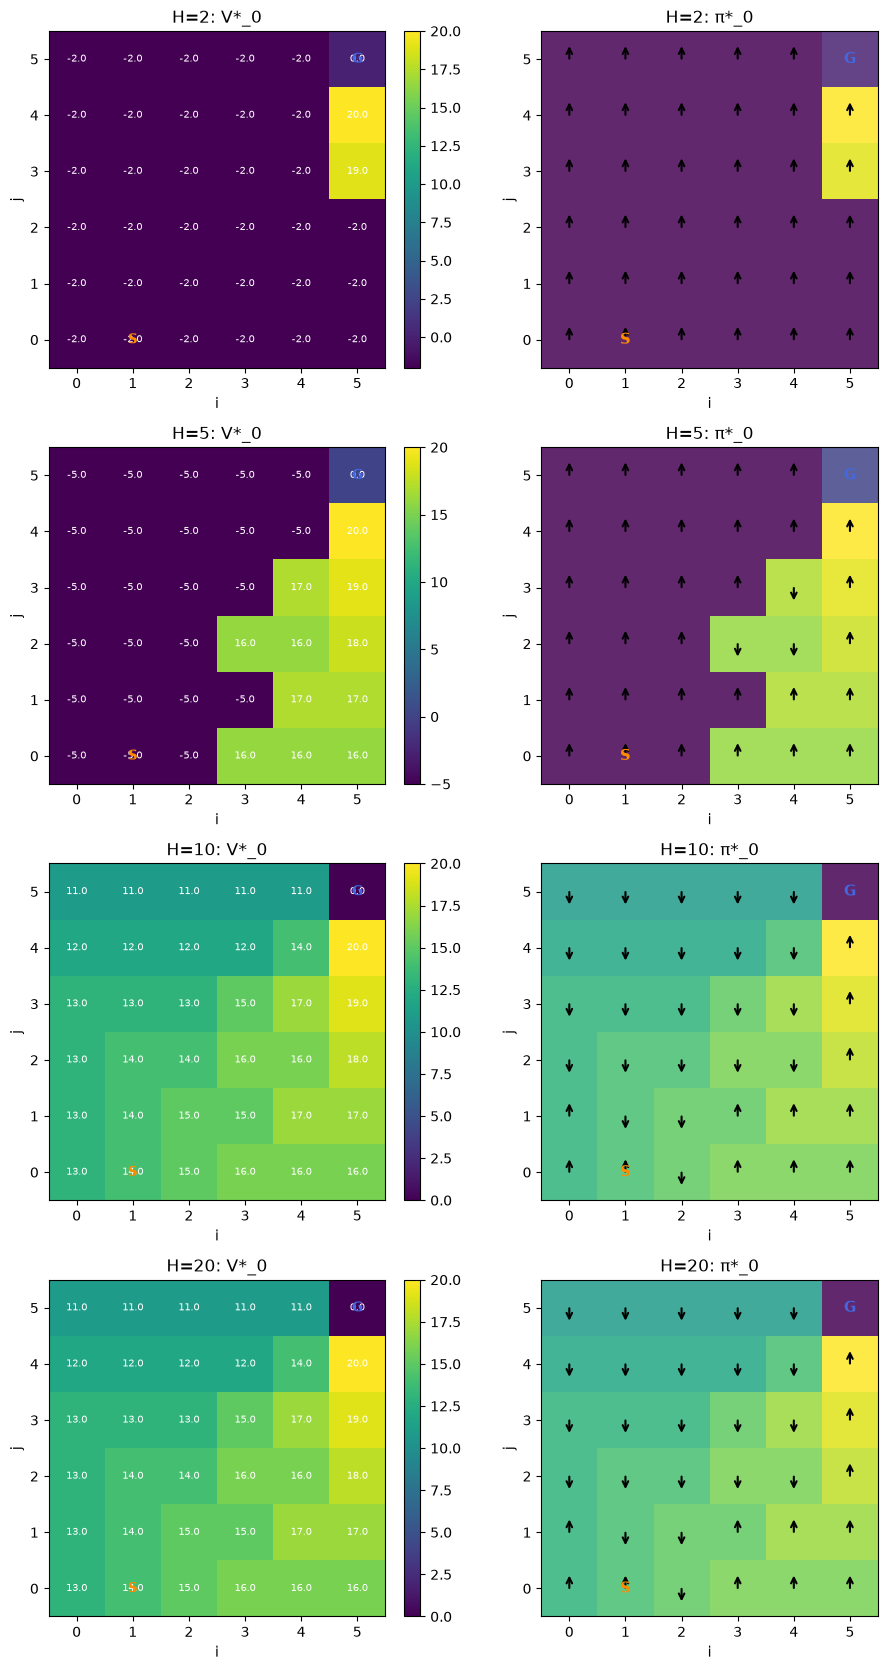

DP horizon sweep: 0.82s
  H=2: V*_0(s0) = -2.00
  H=5: V*_0(s0) = -5.00
  H=10: V*_0(s0) = 14.00
  H=20: V*_0(s0) = 14.00


In [18]:
t0 = time.perf_counter()
dp_sweep = run_dp_horizon_sweep(
    horizons=(2, 5, 10, 20),
    device=device,
    save_dir=SAVE_DIR,
    show=True,
)
print(f"DP horizon sweep: {time.perf_counter() - t0:.2f}s")
for row in dp_sweep:
    print(f"  H={row['horizon']}: V*_0(s0) = {row['V0_initial']:.2f}")

Saved figures/dp_time_slices_H20.png


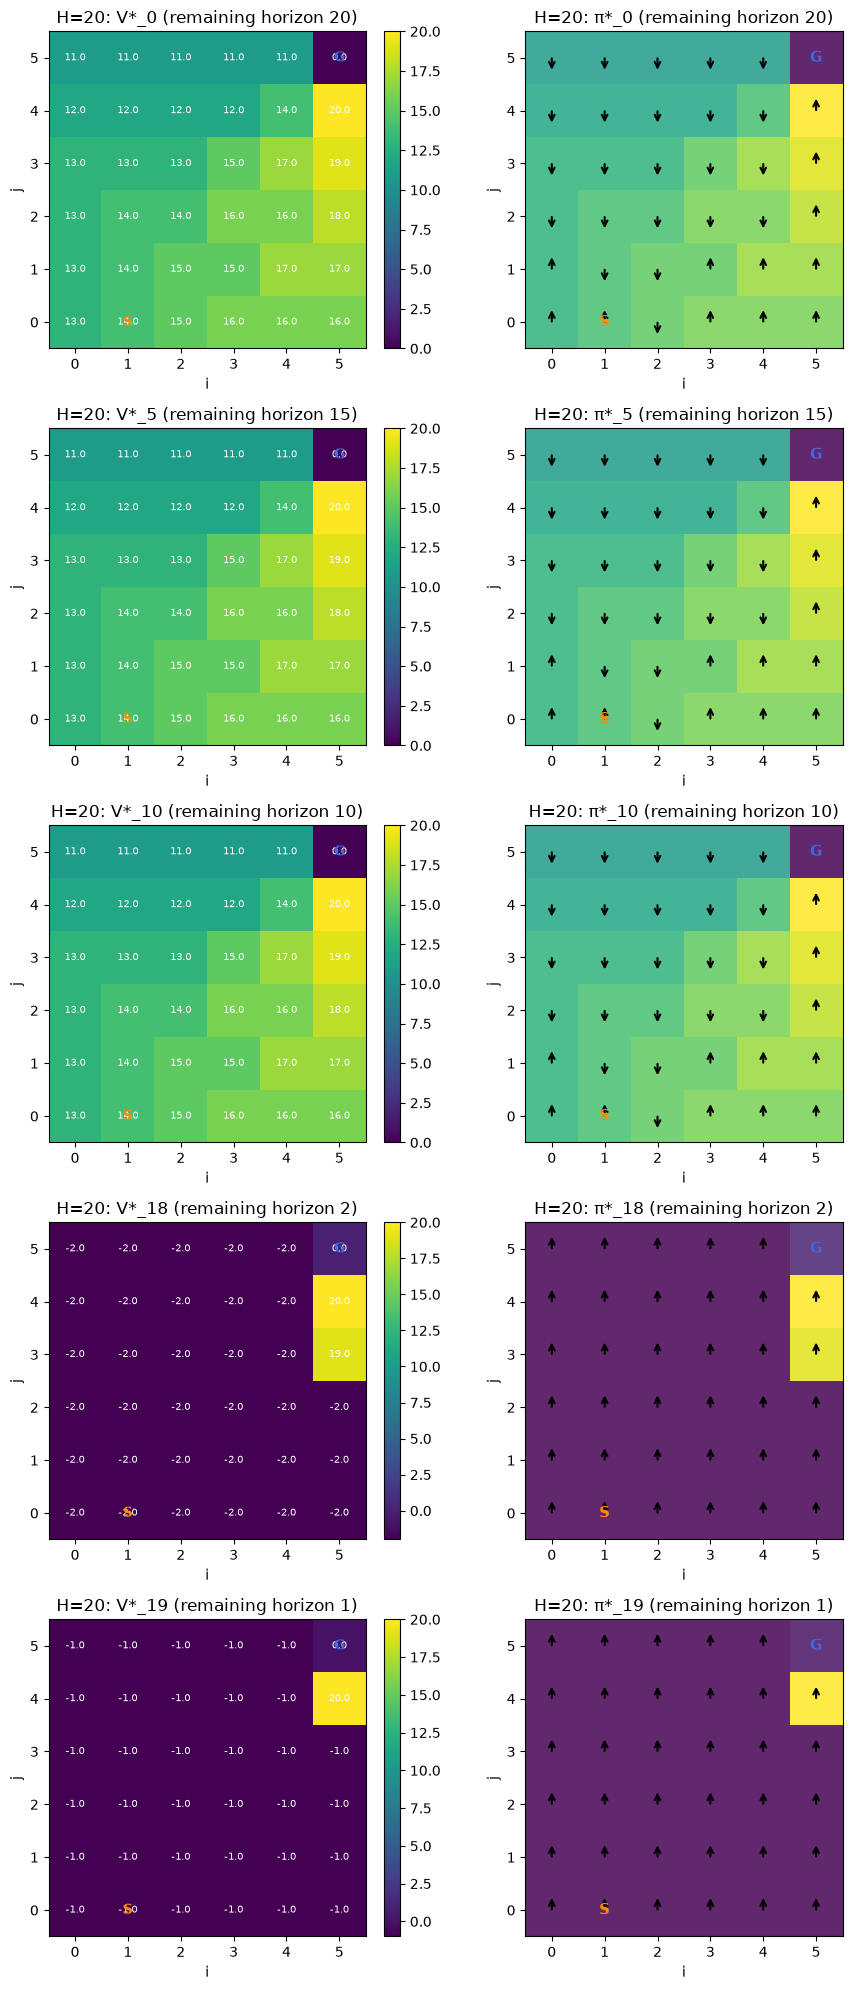

DP time slices: 1.08s
Plotted times t = [0, 5, 10, 18, 19]


In [19]:
t0 = time.perf_counter()
dp_slices = run_dp_time_slices(
    horizon=20,
    device=device,
    save_dir=SAVE_DIR,
    show=True,
)
print(f"DP time slices: {time.perf_counter() - t0:.2f}s")
print(f"Plotted times t = {dp_slices['times']}")

## 4. Section 6.2 — Infinite-horizon value iteration

Initialize $Q$ at zero and watch goal information propagate under Bellman backups.  
Then repeat for $\gamma \in \{0.5, 0.9, 0.99\}$ and record iterations to the same tolerance.

Saved figures/vi_propagation_gamma0.9.png
VI γ=0.9: converged in 12 iters (ε=0.00e+00), V*(s0)=5.94


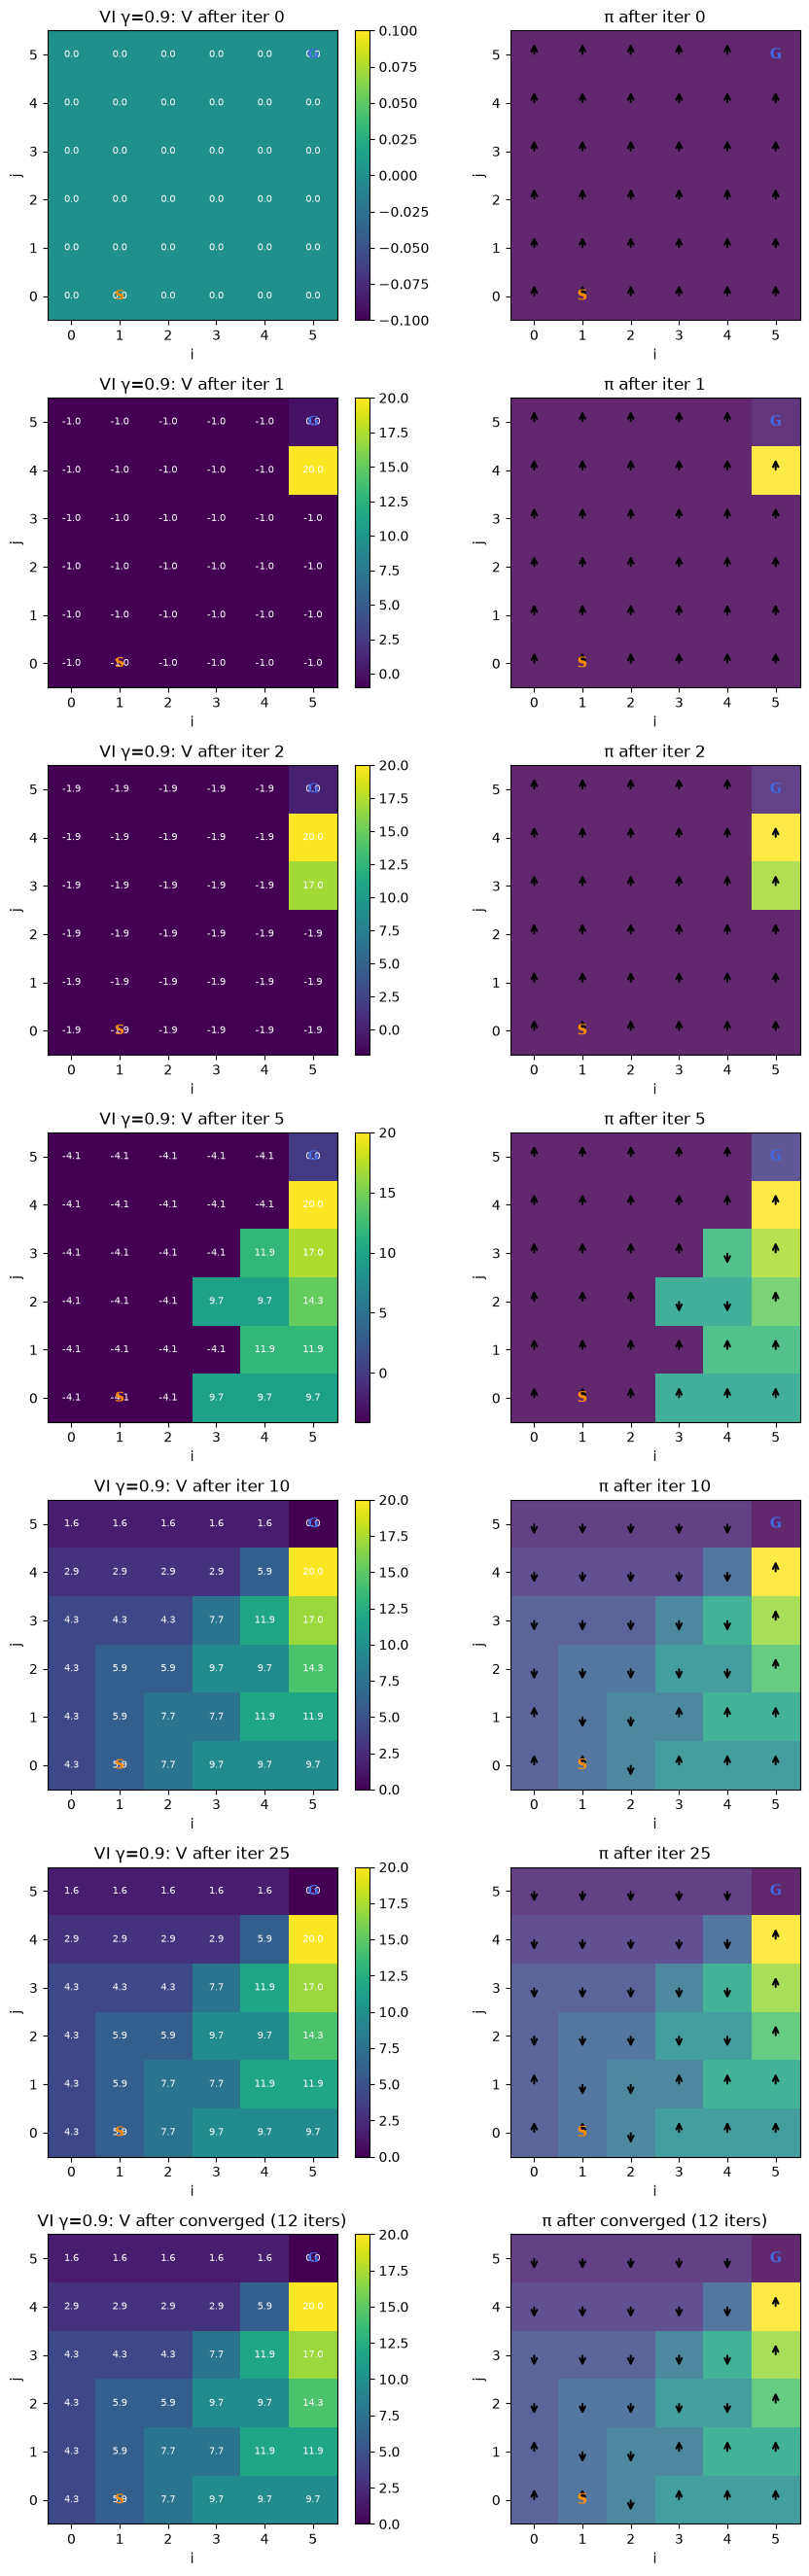

VI propagation: 1.36s
Converged in 12 iters, V*(s0) = 5.94


In [20]:
t0 = time.perf_counter()
vi_prop = run_vi_propagation(
    discount=0.9,
    tolerance=0.01,
    snapshot_iters=(0, 1, 2, 5, 10, 25),
    device=device,
    save_dir=SAVE_DIR,
    show=True,
)
print(f"VI propagation: {time.perf_counter() - t0:.2f}s")
print(
    f"Converged in {vi_prop['n_iters']} iters, "
    f"V*(s0) = {vi_prop['V_star'][mdp.initial_state].item():.2f}"
)

VI γ=0.5: iters=12, ε=0.00e+00, V*(s0)=-1.66
VI γ=0.9: iters=12, ε=0.00e+00, V*(s0)=5.94
VI γ=0.99: iters=12, ε=0.00e+00, V*(s0)=12.98
Saved figures/vi_discount_sweep.png
Saved figures/vi_iterations_vs_discount.png


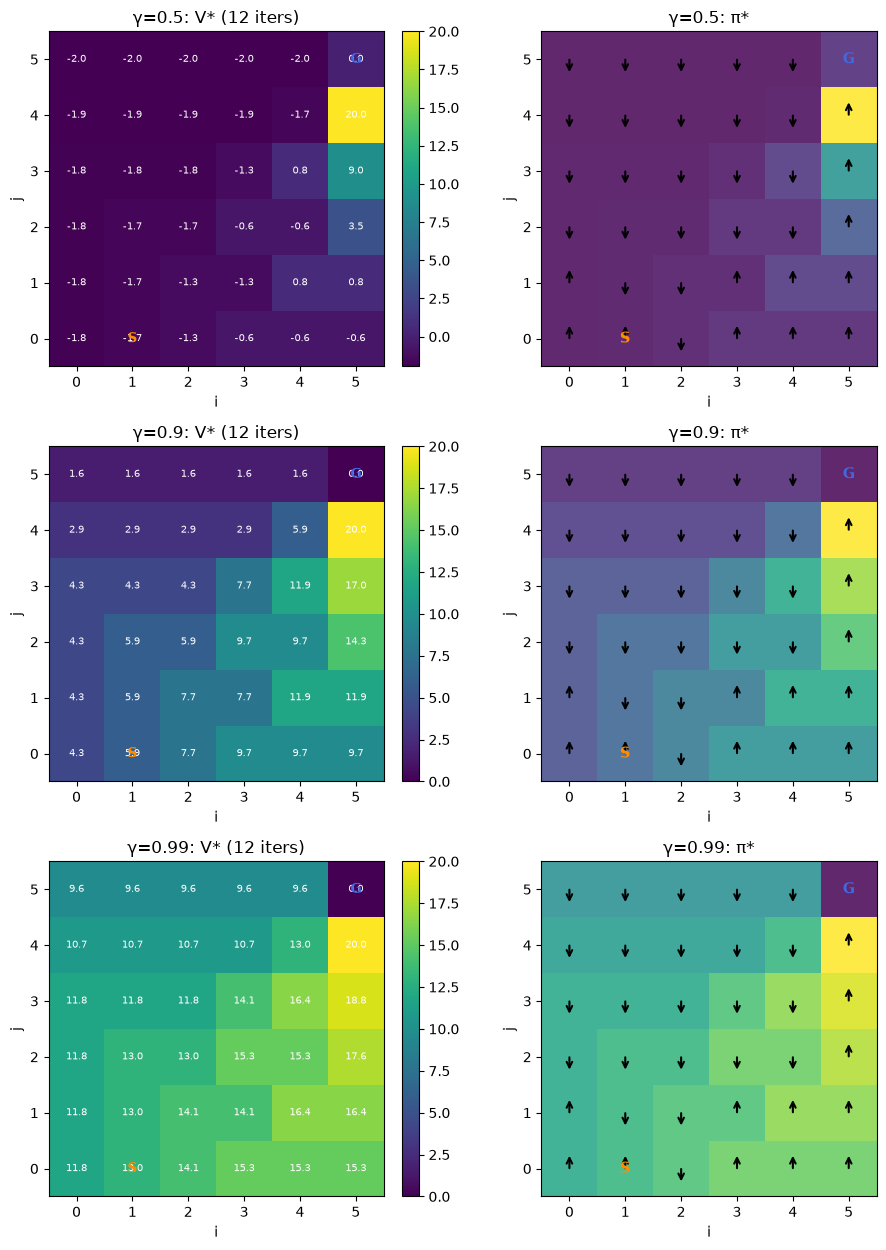

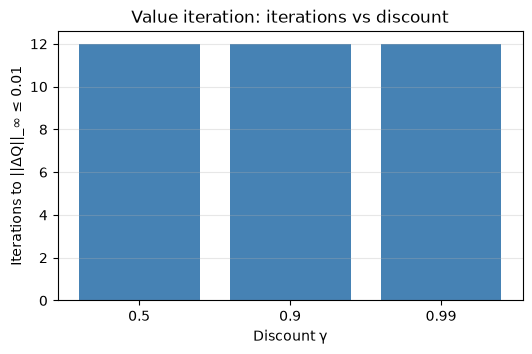

VI discount sweep: 0.67s
   gamma    iters     V*(s0)
    0.50       12      -1.66
    0.90       12       5.94
    0.99       12      12.98


In [21]:
t0 = time.perf_counter()
vi_sweep = run_vi_discount_sweep(
    discounts=(0.5, 0.9, 0.99),
    tolerance=0.01,
    device=device,
    save_dir=SAVE_DIR,
    show=True,
)
print(f"VI discount sweep: {time.perf_counter() - t0:.2f}s")
print(f"{'gamma':>8} {'iters':>8} {'V*(s0)':>10}")
for row in vi_sweep:
    print(f"{row['discount']:8.2f} {row['n_iters']:8d} {row['V_initial']:10.2f}")

## 5. Section 6.3 — Tabular Q-learning

Train on the same infinite-horizon problem as VI. Plot episode returns,  
$E_k = \|Q_k - Q^*_{\mathrm{VI}}\|_\infty$, and policy agreement $A_k$, for $\epsilon \in \{0, 0.1, 0.5\}$.

In [22]:
QL_EPISODES = 1000  # increase if curves look under-trained

t0 = time.perf_counter()
ql = run_qlearning_experiments(
    epsilons=(0.0, 0.1, 0.5),
    discount=0.9,
    num_episodes=QL_EPISODES,
    alpha=0.5,
    tolerance=0.01,
    log_every=25,
    seed=0,
    device=device,
    save_dir=SAVE_DIR,
    show=True,
)
print(f"Q-learning experiments: {time.perf_counter() - t0:.2f}s")
for run in ql["runs"]:
    print(
        f"  ε={run['epsilon']}: final ||Q-Q*||_∞={run['q_errors'][-1]:.3f}, "
        f"agreement={run['agreements'][-1]:.0%}, "
        f"wall={run['elapsed_sec']:.2f}s"
    )

VI reference (γ=0.9): 12 iters, ε=0.00e+00
Q-learning ε=0.0: 1000 episodes in 0.11s, final ||Q-Q*||_∞=14.300, agreement=59%, avg return (last 50)=13.00
Saved figures/ql_policy_eps0.0.png
Q-learning ε=0.1: 1000 episodes in 0.10s, final ||Q-Q*||_∞=8.832, agreement=86%, avg return (last 50)=13.28
Saved figures/ql_policy_eps0.1.png
Q-learning ε=0.5: 1000 episodes in 0.16s, final ||Q-Q*||_∞=1.795, agreement=100%, avg return (last 50)=9.48
Saved figures/ql_policy_eps0.5.png
Saved figures/ql_learning_curves.png
Saved figures/ql_q_error.png
Saved figures/ql_policy_agreement.png
Saved figures/ql_qstar_vi.png
Saved figures/ql_q_learned_eps0.1.png
Q-learning experiments: 1.22s
  ε=0.0: final ||Q-Q*||_∞=14.300, agreement=59%, wall=0.11s
  ε=0.1: final ||Q-Q*||_∞=8.832, agreement=86%, wall=0.10s
  ε=0.5: final ||Q-Q*||_∞=1.795, agreement=100%, wall=0.16s


## 6. One-shot: run everything

Equivalent to `python visualize.py --experiment all`. Useful for timing the full figure suite.

In [23]:
# Uncomment to regenerate every Section 6 figure in one call:
summary = run_all_experiments(save_dir=SAVE_DIR, device=device, show=False, ql_episodes=1000)
print(f"Total wall time: {summary['total_seconds']:.2f}s")

 Environment
Saved figures/environment_wind.png
 Section 6.1 — Dynamic programming
DP H=2: V*_0(s0) = -2.00
DP H=5: V*_0(s0) = -5.00
DP H=10: V*_0(s0) = 14.00
DP H=20: V*_0(s0) = 14.00
Saved figures/dp_horizon_sweep.png
Saved figures/dp_time_slices_H20.png
DP experiments wall time: 1.11s
 Section 6.2 — Value iteration
Saved figures/vi_propagation_gamma0.9.png
VI γ=0.9: converged in 12 iters (ε=0.00e+00), V*(s0)=5.94
VI γ=0.5: iters=12, ε=0.00e+00, V*(s0)=-1.66
VI γ=0.9: iters=12, ε=0.00e+00, V*(s0)=5.94
VI γ=0.99: iters=12, ε=0.00e+00, V*(s0)=12.98
Saved figures/vi_discount_sweep.png
Saved figures/vi_iterations_vs_discount.png
VI experiments wall time: 1.29s
 Section 6.3 — Q-learning
VI reference (γ=0.9): 12 iters, ε=0.00e+00
Q-learning ε=0.0: 1000 episodes in 0.11s, final ||Q-Q*||_∞=14.300, agreement=59%, avg return (last 50)=13.00
Saved figures/ql_policy_eps0.0.png
Q-learning ε=0.1: 1000 episodes in 0.10s, final ||Q-Q*||_∞=8.832, agreement=86%, avg return (last 50)=13.28
Saved figure

## 7. Writeup checklist (Section 7)

Figures written under `figures/`:
- `dp_horizon_sweep.png`, `dp_time_slices_H20.png`, plus `dp_traj_H*.gif`
- `vi_propagation_gamma0.9.png`, `vi_discount_sweep.png`, `vi_iterations_vs_discount.png`, plus `vi_traj_gamma*.gif`
- `ql_learning_curves.png`, `ql_q_error.png`, `ql_policy_agreement.png`, plus per-ε policy / Q plots and `ql_traj_eps*.gif`

Trajectory GIFs animate the greedy rollout growing one step at a time on the policy map.

Use them to answer the five discussion questions in the handout.